In [1]:
# ==== Cell 1: imports and settings ====
from pathlib import Path
import sys, time, copy, types

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

PROJECT = Path("/home/spatel/Desktop/Projects/collective_intelligence/ant_sim/simple_ant_sim")
DATA_DIR = PROJECT / "data/dataset_20261025_104552_105991"
OUT_DIR = PROJECT / "data/eps_models"
USE_FAKE_DATA = False      # True: small fake dataset to test the notebook end to end
RUN_SIM = True             # False: skip the simulator check (Part 4)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
SEED = 0
torch.manual_seed(SEED)
np.random.seed(SEED)

# Step 0: per-step brain model
STEP_BATCH, STEP_EPOCHS, STEP_LR = 512, 2, 1e-3

# Step 1: sequence models
SEQ_LEN, SEQ_STRIDE = 128, 64
SEQ_BATCH, SEQ_EPOCHS, SEQ_LR = 256, 20, 3e-4

# Simulator check
SIM_STEPS, SIM_SEEDS, SIM_EPS = 2000, range(10), [0.1, 0.3, 0.5]
FOOD_PATCHES = [(80, 80), (20, 75)]    # must match how the dataset runs placed food

OUT_DIR.mkdir(parents=True, exist_ok=True)
print("device:", DEVICE)

device: cuda


In [2]:
# ==== Cell 2: state layout and the true rule ====
# One state row = one ant at one step (19 numbers). Layout confirmed against step_ant.
ON_FOOD, AT_HOME, CARRYING = 0, 1, 2
SEE_FOOD, SEE_HOME = slice(3, 7), slice(7, 11)
SMELL_FOOD, SMELL_HOME = slice(11, 15), slice(15, 19)
N_ACTIONS = 4   # up, down, left, right


def sees_target(s):
    """True where the ant can see its current target (food if searching, home if carrying)."""
    carrying = s[:, CARRYING] > 0.5
    target = np.where(carrying[:, None], s[:, SEE_HOME], s[:, SEE_FOOD])
    return target.max(axis=1) > 0


def signal(s):
    """The 4 numbers the brain uses: the target if visible, otherwise the smell."""
    carrying = s[:, CARRYING] > 0.5
    target = np.where(carrying[:, None], s[:, SEE_HOME], s[:, SEE_FOOD])
    smell = np.where(carrying[:, None], s[:, SMELL_HOME], s[:, SMELL_FOOD])
    return np.where(sees_target(s)[:, None], target, smell)


def best_dir(s):
    return signal(s).argmax(axis=1)


def n_ties(s):
    """How many directions share the top signal. 1 = clear choice, 4 = no signal at all."""
    sig = signal(s)
    return (sig == sig.max(axis=1, keepdims=True)).sum(axis=1)


def true_probs(s, eps):
    """True action probabilities: brain with prob 1-eps (split over tied best dirs), uniform with prob eps."""
    sig = signal(s)
    is_best = sig == sig.max(axis=1, keepdims=True)
    k = is_best.sum(axis=1, keepdims=True)
    eps = np.asarray(eps, dtype=np.float64).reshape(-1, 1)
    return is_best * (1 - eps) / k + eps / N_ACTIONS


def true_entropy(s, eps):
    """Lowest possible loss for each row. Only reachable if the model knows the true eps."""
    p = true_probs(s, eps)
    return -(p * np.log(np.clip(p, 1e-12, None))).sum(axis=1)

In [3]:
# ==== Cell 3: normalization (used everywhere: training, sequences and simulator) ====
def normalize(s):
    """Works on any shape (..., 19). See values / 20, each smell block min-max scaled per row."""
    s = s.astype(np.float32).copy()
    s[..., 3:11] /= 20.0
    for blk in (SMELL_FOOD, SMELL_HOME):
        block = s[..., blk]
        lo = block.min(axis=-1, keepdims=True)
        hi = block.max(axis=-1, keepdims=True)
        s[..., blk] = np.where(hi > lo, (block - lo) / np.maximum(hi - lo, 1e-8), 0.0)
    return s

In [4]:
# ==== Cell 4 (optional): fake dataset for testing the notebook ====
def make_fake_run(path, eps, seed, T=300, N=20):
    rng = np.random.default_rng(seed)
    rows = T * N
    s = np.zeros((rows, 19), dtype=np.float32)
    s[:, CARRYING] = rng.random(rows) < 0.4
    s[:, AT_HOME] = rng.random(rows) < 0.05
    s[:, ON_FOOD] = rng.random(rows) < 0.05
    s[:, 3:11] = (rng.random((rows, 8)) < 0.03) * rng.integers(1, 6, (rows, 8))
    s[:, 11:19] = (rng.random((rows, 1)) < 0.6) * rng.random((rows, 8)) * 0.5

    p = true_probs(s, eps)
    action = np.minimum((rng.random((rows, 1)) > p.cumsum(axis=1)).sum(axis=1), N_ACTIONS - 1)

    s, action = s.reshape(T, N, 19), action.reshape(T, N)
    prev = np.zeros((T, N, 4), dtype=np.float32)
    prev[1:] = np.eye(4, dtype=np.float32)[action[:-1]]
    carrying = s[..., CARRYING] > 0.5

    path.mkdir(parents=True, exist_ok=True)
    np.savez(path / "traj.npz", state=s, action=action, prev_action=prev,
             dec_pick=(s[..., ON_FOOD] > 0.5) & ~carrying,
             dec_drop=(s[..., AT_HOME] > 0.5) & carrying,
             delivered=np.zeros(T + 1), epsilon=eps, seed=seed)


if USE_FAKE_DATA:
    DATA_DIR = Path("fake_data")
    RUN_SIM = False
    for split, seeds in {"train": [0, 1, 2, 3], "val": [4], "test": [5]}.items():
        for seed in seeds:
            for eps in np.round(np.arange(0.1, 1.01, 0.1), 1):
                make_fake_run(DATA_DIR / split / f"seed{seed:03d}_eps{eps}",
                              float(eps), seed * 100 + int(eps * 10))
    print("fake data written to", DATA_DIR)

In [5]:
# ==== Cell 5: load runs ====
def load_run(run_dir):
    """One run, kept in (T, N, ...) shape so we still know which ant is which."""
    with np.load(run_dir / "traj.npz") as d:
        return dict(
            name=run_dir.name,
            state=d["state"].astype(np.float32),              # (T, N, 19) raw
            action=d["action"].astype(np.int64),              # (T, N)
            prev_action=d["prev_action"].astype(np.float32),  # (T, N, 4)
            pick=d["dec_pick"].astype(np.float32),            # (T, N)
            drop=d["dec_drop"].astype(np.float32),            # (T, N)
            eps=float(d["epsilon"]),
            seed=int(d["seed"]),
        )


runs = {}
for split in ["train", "val", "test"]:
    run_dirs = sorted(p.parent for p in (DATA_DIR / split).glob("*/traj.npz"))
    runs[split] = [load_run(r) for r in run_dirs]
    eps_values = sorted({r["eps"] for r in runs[split]})
    print(f"{split}: {len(runs[split])} runs   eps values: {eps_values}")

train: 60 runs   eps values: [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
val: 20 runs   eps values: [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
test: 20 runs   eps values: [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]


In [6]:
# ==== Cell 6: sanity checks per run ====
def check_run(run):
    T, N, D = run["state"].shape
    a = run["action"]
    prev = run["prev_action"]
    has_prev = prev[1:].sum(-1) > 0
    prev_matches = (prev[1:].argmax(-1) == a[:-1])[has_prev].mean()
    return dict(run=run["name"], eps=run["eps"], T=T, N=N, D=D,
                action_min=int(a.min()), action_max=int(a.max()),
                any_nan=bool(np.isnan(run["state"]).any()),
                prev_action_matches=round(float(prev_matches), 4))


checks = pd.DataFrame([check_run(r) for split in runs for r in runs[split]])
print(checks.head(10).to_string(index=False))
print()
print("all D == 19:            ", (checks.D == 19).all())
print("actions in 0..3:        ", ((checks.action_min >= 0) & (checks.action_max <= 3)).all())
print("no NaNs:                ", (~checks.any_nan).all())
print("prev_action consistent: ", (checks.prev_action_matches > 0.99).all())

                   run  eps    T   N  D  action_min  action_max  any_nan  prev_action_matches
seed000_eps0.1_p2_a100  0.1 1500 100 19           0           3    False               0.9995
seed000_eps0.2_p2_a100  0.2 1500 100 19           0           3    False               0.9993
seed000_eps0.3_p2_a100  0.3 1500 100 19           0           3    False               0.9994
seed000_eps0.4_p2_a100  0.4 1500 100 19           0           3    False               0.9996
seed000_eps0.5_p2_a100  0.5 1500 100 19           0           3    False               0.9993
seed000_eps0.6_p2_a100  0.6 1500 100 19           0           3    False               0.9999
seed000_eps0.7_p2_a100  0.7 1500 100 19           0           3    False               0.9997
seed000_eps0.8_p2_a100  0.8 1500 100 19           0           3    False               0.9991
seed000_eps0.9_p2_a100  0.9 1500 100 19           0           3    False               0.9983
seed000_eps1.0_p2_a100  1.0 1500 100 19           0         

In [7]:
# ==== Cell 7: does the data follow the rule, and does normalization keep it? ====
rows = []
for r in runs["train"]:
    s = r["state"].reshape(-1, 19)
    a = r["action"].reshape(-1)
    clear = n_ties(s) == 1
    rows.append(dict(eps=r["eps"],
                     follows_rule=(a[clear] == best_dir(s)[clear]).mean(),
                     expected=1 - r["eps"] + r["eps"] / 4,
                     frac_clear_rows=clear.mean()))
print(pd.DataFrame(rows).groupby("eps").mean().round(3))

s_raw = runs["val"][0]["state"].reshape(-1, 19)
s_norm = normalize(s_raw)
print("\nbest_dir unchanged by normalize:", (best_dir(s_raw) == best_dir(s_norm)).mean(), "  (want 1.0)")
print("ties unchanged by normalize:    ", (n_ties(s_raw) == n_ties(s_norm)).mean(), "  (want 1.0)")

     follows_rule  expected  frac_clear_rows
eps                                         
0.1         0.925     0.925            0.639
0.2         0.850     0.850            0.651
0.3         0.775     0.775            0.653
0.4         0.701     0.700            0.631
0.5         0.625     0.625            0.638
0.6         0.550     0.550            0.602
0.7         0.475     0.475            0.603
0.8         0.399     0.400            0.574
0.9         0.326     0.325            0.454
1.0         0.249     0.250            0.202

best_dir unchanged by normalize: 1.0   (want 1.0)
ties unchanged by normalize:     1.0   (want 1.0)


In [8]:
# ==== Cell 8: flat tables (one row per ant-step) ====
def flatten(run_list):
    return dict(
        state=normalize(np.concatenate([r["state"].reshape(-1, 19) for r in run_list])),
        action=np.concatenate([r["action"].reshape(-1) for r in run_list]),
        pick=np.concatenate([r["pick"].reshape(-1) for r in run_list]),
        drop=np.concatenate([r["drop"].reshape(-1) for r in run_list]),
        eps=np.concatenate([np.full(r["action"].size, r["eps"], dtype=np.float32) for r in run_list]),
    )


flat = {split: flatten(runs[split]) for split in ["train", "val"]}   # test kept aside for final reporting
for split, f in flat.items():
    print(f"{split}: {len(f['action']):,} rows")

train: 9,000,000 rows
val: 3,000,000 rows


In [9]:
# ==== Cell 9: the brain model ====
class BrainModel(nn.Module):
    """Scores each direction with one shared network, using only the blocks the rule uses
    (target and smell picked by 'carrying'). With no signal, all 4 directions look identical,
    so the output is exactly uniform."""
    def __init__(self, hidden=64):
        super().__init__()
        self.score = nn.Sequential(nn.Linear(5, hidden), nn.ReLU(),
                                   nn.Linear(hidden, hidden), nn.ReLU(),
                                   nn.Linear(hidden, 1))
        self.pick_head = nn.Linear(3, 1)
        self.drop_head = nn.Linear(3, 1)

    def forward(self, x):                                                    # x: (B, 19)
        flags = x[:, :3]
        carrying = flags[:, CARRYING:CARRYING + 1] > 0.5                     # (B, 1)
        target = torch.where(carrying, x[:, SEE_HOME], x[:, SEE_FOOD])       # (B, 4)
        smell = torch.where(carrying, x[:, SMELL_HOME], x[:, SMELL_FOOD])    # (B, 4)
        per_dir = torch.stack([target, smell], dim=-1)                       # (B, 4, 2)
        tokens = torch.cat([per_dir, flags[:, None, :].expand(-1, 4, -1)], dim=-1)  # (B, 4, 5)
        a_logit = self.score(tokens).squeeze(-1)                             # (B, 4)
        return a_logit, self.pick_head(flags).squeeze(-1), self.drop_head(flags).squeeze(-1)


def mixture_nll(a_logit, action, eps):
    """-log P(action) when the ant follows the brain with prob 1-eps and moves uniformly with prob eps."""
    p_brain = a_logit.softmax(-1).gather(1, action[:, None]).squeeze(1)
    return -torch.log((1 - eps) * p_brain + eps / N_ACTIONS + 1e-12)

In [10]:
# ==== Cell 10: train and save the brain model ====
def train_step_model(model, f, epochs, batch, lr):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    S, A = torch.from_numpy(f["state"]), torch.from_numpy(f["action"])
    P, D, E = torch.from_numpy(f["pick"]), torch.from_numpy(f["drop"]), torch.from_numpy(f["eps"])
    model.train()
    for epoch in range(1, epochs + 1):
        perm = torch.randperm(len(A))
        start_time, total, count = time.time(), 0.0, 0
        for start in range(0, len(A), batch):
            idx = perm[start:start + batch]
            a_logit, p_logit, d_logit = model(S[idx].to(DEVICE))
            loss_action = mixture_nll(a_logit, A[idx].to(DEVICE), E[idx].to(DEVICE)).mean()
            loss_pick = F.binary_cross_entropy_with_logits(p_logit, P[idx].to(DEVICE))
            loss_drop = F.binary_cross_entropy_with_logits(d_logit, D[idx].to(DEVICE))
            loss = loss_action + loss_pick + loss_drop

            opt.zero_grad()
            loss.backward()
            opt.step()

            total += loss_action.item()
            count += 1
        print(f"epoch {epoch}: action loss {total / count:.4f}   ({time.time() - start_time:.0f} s)")


step_model = BrainModel().to(DEVICE)
train_step_model(step_model, flat["train"], STEP_EPOCHS, STEP_BATCH, STEP_LR)
torch.save(step_model.state_dict(), OUT_DIR / "brain_model.pt")
print("saved", OUT_DIR / "brain_model.pt")

epoch 1: action loss 1.1579   (32 s)
epoch 2: action loss 1.1541   (39 s)
saved /home/spatel/Desktop/Projects/collective_intelligence/ant_sim/simple_ant_sim/data/eps_models/brain_model.pt


In [11]:
# ==== Cell 11: brain report (did the model learn the rule?) ====
@torch.no_grad()
def predict_step_model(model, f, batch=65536):
    model.eval()
    probs, pick, drop = [], [], []
    for start in range(0, len(f["action"]), batch):
        s = torch.from_numpy(f["state"][start:start + batch]).to(DEVICE)
        a_logit, p_logit, d_logit = model(s)
        probs.append(a_logit.softmax(-1).cpu().numpy())
        pick.append((p_logit > 0).cpu().numpy())
        drop.append((d_logit > 0).cpu().numpy())
    model.train()
    return np.concatenate(probs), np.concatenate(pick), np.concatenate(drop)


val_probs_step, val_pick, val_drop = predict_step_model(step_model, flat["val"])
s, a, e = flat["val"]["state"], flat["val"]["action"], flat["val"]["eps"]
pred, best = val_probs_step.argmax(1), best_dir(s)
clear = n_ties(s) == 1
no_signal = n_ties(s) == 4
by_target = clear & sees_target(s)
by_smell = clear & ~sees_target(s)

p_brain = val_probs_step[np.arange(len(a)), a]
nll = -np.log((1 - e) * p_brain + e / N_ACTIONS + 1e-12)
spread = val_probs_step[no_signal].max(1) - val_probs_step[no_signal].min(1)

print("===== val =====")
print(f"agrees with rule, clear rows: {(pred[clear] == best[clear]).mean():.4f}   (want 1.0)")
print(f"   target-driven rows:        {(pred[by_target] == best[by_target]).mean():.4f}")
print(f"   smell-driven rows:         {(pred[by_smell] == best[by_smell]).mean():.4f}")
print(f"confidence on clear rows:     {val_probs_step[clear].max(1).mean():.4f}   (want close to 1.0)")
print(f"uniform when no signal:       max spread {spread.max():.6f}   (want 0)")
print(f"action loss above floor:      {nll.mean() - true_entropy(s, e).mean():.4f}   (want 0)")
for label, true, guess in [("pick", flat["val"]["pick"] > 0.5, val_pick),
                           ("drop", flat["val"]["drop"] > 0.5, val_drop)]:
    tp = (true & guess).sum()
    print(f"{label}: precision {tp / max(guess.sum(), 1):.3f}  recall {tp / max(true.sum(), 1):.3f}")

===== val =====
agrees with rule, clear rows: 1.0000   (want 1.0)
   target-driven rows:        0.9995
   smell-driven rows:         1.0000
confidence on clear rows:     0.9984   (want close to 1.0)
uniform when no signal:       max spread 0.000000   (want 0)
action loss above floor:      0.0011   (want 0)
pick: precision 1.000  recall 1.000
drop: precision 1.000  recall 1.000


In [12]:
# ==== Cell 12 (optional): remaining mistakes by smell margin (RAW units), then free memory ====
raw_val = np.concatenate([r["state"].reshape(-1, 19) for r in runs["val"]])
carrying = raw_val[:, CARRYING] > 0.5
smell_raw = np.where(carrying[:, None], raw_val[:, SMELL_HOME], raw_val[:, SMELL_FOOD])

top2 = np.sort(smell_raw[by_smell], axis=1)[:, -2:]
margin = top2[:, 1] - top2[:, 0]
ok = pred[by_smell] == best[by_smell]

bins = [0, 0.01, 0.03, 0.1, 0.3, 1.01]
idx = np.digitize(margin, bins) - 1
for i in range(len(bins) - 1):
    sel = idx == i
    if sel.any():
        print(f"margin {bins[i]:.2f} to {bins[i + 1]:.2f}: rows {sel.sum():>9,}   agree {ok[sel].mean():.3f}")

del flat, raw_val, smell_raw    # about 1 GB, not needed after this point

margin 0.00 to 0.01: rows   202,754   agree 1.000
margin 0.01 to 0.03: rows   652,429   agree 1.000
margin 0.03 to 0.10: rows   505,030   agree 1.000
margin 0.10 to 0.30: rows    97,903   agree 1.000
margin 0.30 to 1.01: rows    24,531   agree 1.000


In [13]:
# ==== Cell 13: simulator setup and the learned brain ====
sys.path.insert(0, str(PROJECT))
from simulation import Simulation
from config import Config

sim_mod = sys.modules[Simulation.__module__]
original_decide = sim_mod.decide
cpu_brain = copy.deepcopy(step_model).cpu().eval()


@torch.no_grad()
def learned_decide(ant, local, rng, cfg):
    x = torch.from_numpy(normalize(ant.obs[None]))           # SAME normalize as training
    a_logit, p_logit, d_logit = cpu_brain(x)
    if rng.random() < cfg.epsilon:
        d = int(rng.integers(N_ACTIONS))                       # random move
    else:
        prob = a_logit.softmax(-1)[0].numpy().astype(np.float64)
        d = int(rng.choice(N_ACTIONS, p=prob / prob.sum()))    # brain move (sampling splits ties)
    action = np.zeros(N_ACTIONS, dtype=np.float32)
    action[d] = 1.0
    return types.SimpleNamespace(action=action, pick=bool(p_logit.item() > 0),
                                 drop=bool(d_logit.item() > 0), mode="learned")


def run_sim(eps, seed, decide_fn, T=SIM_STEPS):
    """Food delivered after T steps with the given brain."""
    sim_mod.decide = decide_fn
    try:
        sim = Simulation(Config(epsilon=eps, seed=seed))
        for x, y in FOOD_PATCHES:
            sim.world.add_food(x, y, radius=4, amount_per_cell=5)
        for _ in range(T):
            sim.step()
        return sim.world.food_delivered
    finally:
        sim_mod.decide = original_decide                       # always put the real brain back

In [14]:
# ==== Cell 14: original vs learned brain in the simulator ====
if RUN_SIM:
    n_threads = torch.get_num_threads()
    torch.set_num_threads(1)               # one-row model calls are faster single-threaded
    rows = []
    for eps in SIM_EPS:
        for seed in SIM_SEEDS:
            rows.append(dict(eps=eps, seed=seed,
                             original=run_sim(eps, seed, original_decide),
                             learned=run_sim(eps, seed, learned_decide)))
            print(rows[-1])
    torch.set_num_threads(n_threads)
    sim_results = pd.DataFrame(rows)
    print(sim_results.groupby("eps")[["original", "learned"]].agg(["mean", "std"]).round(1))

{'eps': 0.1, 'seed': 0, 'original': 359, 'learned': 356}
{'eps': 0.1, 'seed': 1, 'original': 336, 'learned': 297}
{'eps': 0.1, 'seed': 2, 'original': 461, 'learned': 262}
{'eps': 0.1, 'seed': 3, 'original': 318, 'learned': 261}
{'eps': 0.1, 'seed': 4, 'original': 258, 'learned': 382}
{'eps': 0.1, 'seed': 5, 'original': 362, 'learned': 292}
{'eps': 0.1, 'seed': 6, 'original': 468, 'learned': 388}
{'eps': 0.1, 'seed': 7, 'original': 402, 'learned': 247}
{'eps': 0.1, 'seed': 8, 'original': 351, 'learned': 285}
{'eps': 0.1, 'seed': 9, 'original': 379, 'learned': 435}
{'eps': 0.3, 'seed': 0, 'original': 285, 'learned': 309}
{'eps': 0.3, 'seed': 1, 'original': 283, 'learned': 323}
{'eps': 0.3, 'seed': 2, 'original': 462, 'learned': 355}
{'eps': 0.3, 'seed': 3, 'original': 299, 'learned': 297}
{'eps': 0.3, 'seed': 4, 'original': 264, 'learned': 260}
{'eps': 0.3, 'seed': 5, 'original': 422, 'learned': 315}
{'eps': 0.3, 'seed': 6, 'original': 417, 'learned': 412}
{'eps': 0.3, 'seed': 7, 'origin

In [15]:
# ==== Cell 15: one long sequence per ant ====
@torch.no_grad()
def brain_probs(states_norm, batch=65536):
    """Brain model's predicted odds for each state. Input (..., 19) normalized, output (..., 4)."""
    step_model.eval()
    shape = states_norm.shape[:-1]
    flat_s = torch.from_numpy(np.ascontiguousarray(states_norm.reshape(-1, 19)))
    out = []
    for start in range(0, len(flat_s), batch):
        a_logit, _, _ = step_model(flat_s[start:start + batch].to(DEVICE))
        out.append(a_logit.softmax(-1).cpu().numpy())
    return np.concatenate(out).reshape(*shape, 4).astype(np.float32)


def build_sequences(run_list, with_actions=True, with_brain=False, shuffle=False, seed=0):
    """Returns X (ants, T, d), Y (ants, T), EPS (ants,).
    Columns of X: [normalized state (19) | brain odds (4) if with_brain | previous action (4) if with_actions].
    The state is always the first 19 columns.
    shuffle=True reorders each ant's time steps at random, keeping each state paired with its action."""
    assert not (shuffle and with_actions), "previous action means nothing once time is shuffled"
    rng = np.random.default_rng(seed)
    X, Y, EPS = [], [], []
    for r in run_list:
        s = normalize(r["state"])                                   # (T, N, 19)
        parts = [s]
        if with_brain:
            parts.append(brain_probs(s))
        if with_actions:
            parts.append(r["prev_action"])
        x = np.concatenate(parts, axis=-1).transpose(1, 0, 2)       # (N, T, d)
        y = r["action"].T                                           # (N, T)
        if shuffle:
            order = np.argsort(rng.random(y.shape), axis=1)         # a different random order per ant
            x = np.take_along_axis(x, order[..., None], axis=1)
            y = np.take_along_axis(y, order, axis=1)
        X.append(np.ascontiguousarray(x, dtype=np.float32))
        Y.append(np.ascontiguousarray(y))
        EPS.append(np.full(x.shape[0], r["eps"], dtype=np.float32))
    return np.concatenate(X), np.concatenate(Y), np.concatenate(EPS)

In [16]:
# ==== Cell 16: windows and batches ====
def all_windows(n_ants, T, seq_len, stride):
    """Every (ant, start) pair. One window = seq_len consecutive steps of one ant."""
    starts = np.arange(0, T - seq_len + 1, stride)
    ants, t0 = np.meshgrid(np.arange(n_ants), starts, indexing="ij")
    return ants.ravel(), t0.ravel()


def get_batch(X, Y, EPS, ants, t0, seq_len):
    t = t0[:, None] + np.arange(seq_len)[None, :]     # (B, seq_len) time indices
    x = X[ants[:, None], t]                            # (B, seq_len, d)
    y = Y[ants[:, None], t]                            # (B, seq_len)
    return torch.from_numpy(x), torch.from_numpy(y), EPS[ants]

In [17]:
# ==== Cell 17: the sequence model (no eps input) ====
class AntGPT(nn.Module):
    def __init__(self, d_in, d_model=64, n_layers=3, n_heads=4, max_len=SEQ_LEN):
        super().__init__()
        self.inp = nn.Linear(d_in, d_model)
        self.pos = nn.Embedding(max_len, d_model)
        layer = nn.TransformerEncoderLayer(d_model, n_heads, 4 * d_model, dropout=0.0,
                                           batch_first=True, norm_first=True)
        self.blocks = nn.TransformerEncoder(layer, n_layers, enable_nested_tensor=False)
        self.norm = nn.LayerNorm(d_model)
        self.out = nn.Linear(d_model, N_ACTIONS)

    def forward(self, x):                                    # x: (B, T, d_in)
        T = x.shape[1]
        h = self.inp(x) + self.pos(torch.arange(T, device=x.device))
        mask = nn.Transformer.generate_square_subsequent_mask(T, device=x.device)
        h = self.blocks(h, mask=mask, is_causal=True)        # step t only sees steps 0..t
        return self.out(self.norm(h))                        # (B, T, 4) logits

In [18]:
# ==== Cell 18: train and collect predictions ====
def train_seq_model(model, data, epochs, batch, lr):
    X, Y, EPS = data
    ants, t0 = all_windows(len(X), X.shape[1], SEQ_LEN, SEQ_STRIDE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    model.train()
    for epoch in range(1, epochs + 1):
        order = np.random.permutation(len(ants))
        start_time, total, count = time.time(), 0.0, 0
        for start in range(0, len(order), batch):
            sel = order[start:start + batch]
            x, y, _ = get_batch(X, Y, EPS, ants[sel], t0[sel], SEQ_LEN)
            logits = model(x.to(DEVICE))
            loss = F.cross_entropy(logits.reshape(-1, N_ACTIONS), y.reshape(-1).to(DEVICE))

            opt.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()

            total += loss.item()
            count += 1
        print(f"   epoch {epoch:>2}: loss {total / count:.4f}   ({time.time() - start_time:.0f} s)")


@torch.no_grad()
def collect_seq(model, data, n_windows=3000, batch=256, seed=0):
    """Returns probs (W, L, 4), actions (W, L), normalized states (W, L, 19), eps (W,).
    Windows are picked with a fixed seed, so every model sees the same ants and start times."""
    X, Y, EPS = data
    ants, t0 = all_windows(len(X), X.shape[1], SEQ_LEN, SEQ_STRIDE)
    keep = np.random.default_rng(seed).choice(len(ants), size=min(n_windows, len(ants)), replace=False)
    ants, t0 = ants[keep], t0[keep]

    model.eval()
    probs, acts, states, eps = [], [], [], []
    for start in range(0, len(ants), batch):
        x, y, e = get_batch(X, Y, EPS, ants[start:start + batch], t0[start:start + batch], SEQ_LEN)
        probs.append(model(x.to(DEVICE)).softmax(-1).cpu().numpy())
        acts.append(y.numpy())
        states.append(x[..., :19].numpy())
        eps.append(e)
    model.train()
    return np.concatenate(probs), np.concatenate(acts), np.concatenate(states), np.concatenate(eps)

In [19]:
# ==== Cell 19: train all four sequence models ====
# A: the main model. Sees states and previous actions; must learn the rule and eps itself.
# B: also given the brain's odds, so it only has to learn eps.
# C: states only. Behavior is still visible through how the states change step to step.
# D: states only, time order shuffled. Keeps WHERE the ant spent its time, destroys HOW it moved.
#    Whatever D can read is eps leaking from places, not from behavior.
EXPERIMENTS = {
    "A states+actions":        dict(with_actions=True),
    "B states+actions+rule":   dict(with_actions=True, with_brain=True),
    "C states only":           dict(with_actions=False),
    "D states only, shuffled": dict(with_actions=False, shuffle=True),
}


def run_experiment(name, opts):
    start_time = time.time()
    data = {split: build_sequences(runs[split], **opts) for split in ["train", "val"]}
    d_in = data["train"][0].shape[-1]
    print(f"== {name}: input size {d_in}, train X {data['train'][0].shape}")

    model = AntGPT(d_in=d_in).to(DEVICE)
    train_seq_model(model, data["train"], SEQ_EPOCHS, SEQ_BATCH, SEQ_LR)
    preds = collect_seq(model, data["val"])
    torch.save(model.state_dict(), OUT_DIR / f"seq_{name.split()[0]}.pt")

    del data
    print(f"   done in {(time.time() - start_time) / 60:.1f} min\n")
    return model, preds


seq_models, seq_preds = {}, {}
for name, opts in EXPERIMENTS.items():
    seq_models[name], seq_preds[name] = run_experiment(name, opts)

# A, B and C see identical windows, so their numbers compare directly (D's windows are shuffled by design)
ref = seq_preds["A states+actions"]
for name in ["B states+actions+rule", "C states only"]:
    assert np.array_equal(seq_preds[name][1], ref[1]) and np.allclose(seq_preds[name][2], ref[2])
print("A, B, C use identical validation windows")

== A states+actions: input size 23, train X (6000, 1500, 23)
   epoch  1: loss 1.3044   (8 s)
   epoch  2: loss 1.2265   (8 s)
   epoch  3: loss 1.2052   (8 s)
   epoch  4: loss 1.1959   (8 s)
   epoch  5: loss 1.1905   (8 s)
   epoch  6: loss 1.1868   (8 s)
   epoch  7: loss 1.1842   (8 s)
   epoch  8: loss 1.1820   (8 s)
   epoch  9: loss 1.1803   (8 s)
   epoch 10: loss 1.1789   (8 s)
   epoch 11: loss 1.1776   (8 s)
   epoch 12: loss 1.1764   (8 s)
   epoch 13: loss 1.1756   (8 s)
   epoch 14: loss 1.1746   (8 s)
   epoch 15: loss 1.1737   (8 s)
   epoch 16: loss 1.1730   (8 s)
   epoch 17: loss 1.1723   (8 s)
   epoch 18: loss 1.1717   (8 s)
   epoch 19: loss 1.1711   (8 s)
   epoch 20: loss 1.1706   (8 s)
   done in 2.7 min

== B states+actions+rule: input size 27, train X (6000, 1500, 27)
   epoch  1: loss 1.2253   (8 s)
   epoch  2: loss 1.1790   (8 s)
   epoch  3: loss 1.1688   (8 s)
   epoch  4: loss 1.1652   (8 s)
   epoch  5: loss 1.1638   (8 s)
   epoch  6: loss 1.1629   (

In [20]:
# ==== Cell 20: one analysis function for any sequence model ====
BUCKETS = {"0": slice(0, 1), "1-7": slice(1, 8), "8-31": slice(8, 32),
           "32-63": slice(32, 64), "64-127": slice(64, SEQ_LEN)}
RULE_EPS_MAX = 0.7   # near eps = 1.0 the correct prediction is almost uniform, so "agrees with rule" means nothing


def summarize_model(probs, acts, states, eps):
    """Returns (by_history, by_eps, scores) for one model's predictions on validation windows."""
    W, L, _ = probs.shape
    s = states.reshape(-1, 19)
    rows_eps = np.repeat(eps, L)

    floor = true_entropy(s, rows_eps).reshape(W, L)
    nll = -np.log(np.take_along_axis(probs, acts[..., None], axis=-1)[..., 0] + 1e-12)
    gap = nll - floor                                              # loss above the best possible

    clear = (n_ties(s) == 1).reshape(W, L)
    best = best_dir(s).reshape(W, L)
    rule_ok = probs.argmax(-1) == best
    p_best = np.take_along_axis(probs, best[..., None], axis=-1)[..., 0]
    eps_hat = np.clip((1 - p_best) / 0.75, 0, 1)                   # eps the model "believes"
    rule_rows = clear & (eps <= RULE_EPS_MAX + 1e-6)[:, None]

    by_history = pd.DataFrame([
        dict(history=name, gap=gap[:, sl].mean(),
             rule_agreement=rule_ok[:, sl][rule_rows[:, sl]].mean())
        for name, sl in BUCKETS.items()
    ]).set_index("history")

    rows = []
    for e in np.unique(eps):
        m = np.isclose(eps, e)
        row = {"true_eps": round(float(e), 1)}
        for name, sl in BUCKETS.items():
            row[name] = eps_hat[m, sl][clear[m, sl]].mean()
        row["late_gap"] = gap[m, BUCKETS["64-127"]].mean()
        rows.append(row)
    by_eps = pd.DataFrame(rows).set_index("true_eps")

    late = by_eps["64-127"]
    true = late.index.values
    clean = true <= 0.7
    slope, intercept = np.polyfit(true, late.values, 1)

    eps_grid = np.unique(eps)
    p_mix = np.mean([true_probs(s, np.full(len(s), e)) for e in eps_grid], axis=0)
    nll_mix = -np.log(p_mix[np.arange(len(s)), acts.reshape(-1)] + 1e-12)

    scores = {
        "gap, no-history ideal": (nll_mix - floor.reshape(-1)).mean(),
        "gap, history 0": gap[:, 0].mean(),
        "gap, history 64-127": gap[:, BUCKETS["64-127"]].mean(),
        "rule agreement, 64-127 (eps<=0.7)": by_history.loc["64-127", "rule_agreement"],
        "eps error, all eps": np.abs(late.values - true).mean(),
        "eps error, eps <= 0.7": np.abs(late.values[clean] - true[clean]).mean(),
        "eps slope (want 1)": slope,
        "eps intercept (want 0)": intercept,
    }
    return by_history, by_eps, scores


results = {name: summarize_model(*preds) for name, preds in seq_preds.items()}

In [21]:
# ==== Cell 21: comparison tables ====
pd.set_option("display.width", 200)

print("===== headline scores =====")
print(pd.DataFrame({name: r[2] for name, r in results.items()}).round(4))

print("\n===== loss gap by history =====")
print(pd.DataFrame({name: r[0]["gap"] for name, r in results.items()}).round(4))

print("\n===== implied eps with NO history (single-state leak) =====")
print(pd.DataFrame({name: r[1]["0"] for name, r in results.items()}).round(3))

print("\n===== implied eps after 64-127 steps of history =====")
print(pd.DataFrame({name: r[1]["64-127"] for name, r in results.items()}).round(3))

===== headline scores =====
                                   A states+actions  B states+actions+rule  C states only  D states only, shuffled
gap, no-history ideal                        0.0459                 0.0459         0.0459                   0.0474
gap, history 0                               0.0558                 0.0322         0.0620                   0.0658
gap, history 64-127                          0.0234                 0.0089         0.0267                   0.0307
rule agreement, 64-127 (eps<=0.7)            0.9735                 0.9994         0.9719                   0.9726
eps error, all eps                           0.0724                 0.0397         0.0719                   0.0789
eps error, eps <= 0.7                        0.0780                 0.0273         0.0691                   0.0990
eps slope (want 1)                           0.7578                 0.8364         0.7175                   0.7531
eps intercept (want 0)                       0.1706 

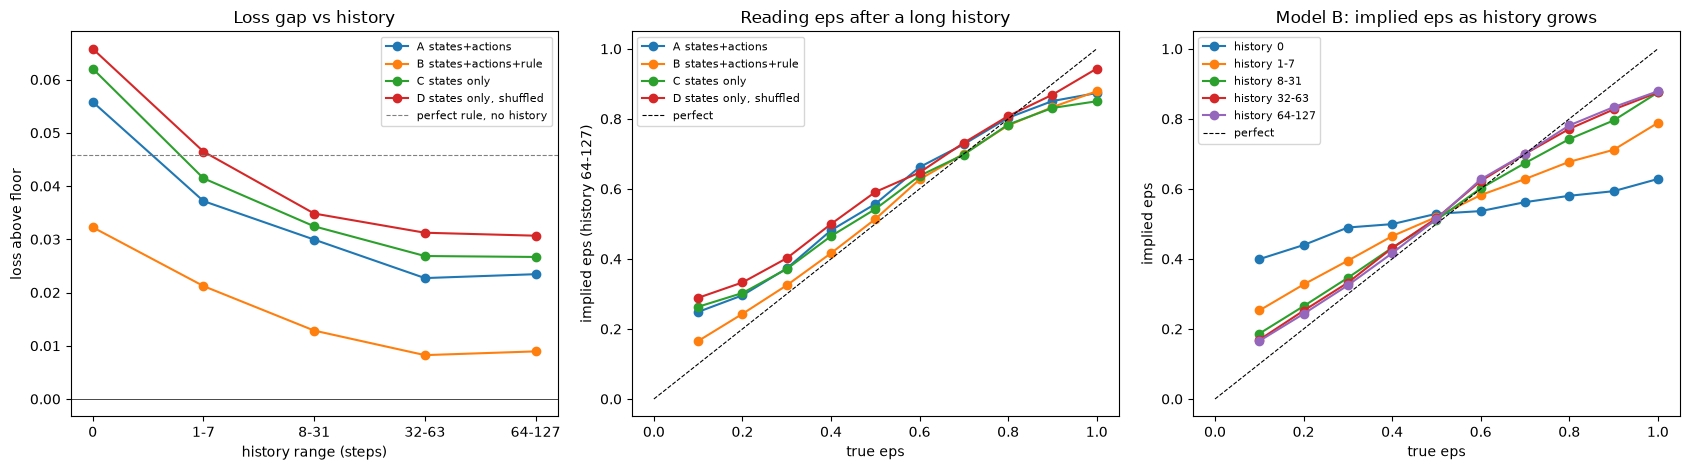

In [22]:
# ==== Cell 22: plots ====
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

for name, (by_history, by_eps, _) in results.items():
    axes[0].plot(by_history.index, by_history["gap"], marker="o", label=name)
    axes[1].plot(by_eps.index, by_eps["64-127"], marker="o", label=name)
ideal = results["A states+actions"][2]["gap, no-history ideal"]
axes[0].axhline(ideal, color="gray", ls="--", lw=0.8, label="perfect rule, no history")
axes[0].axhline(0, color="black", lw=0.5)
axes[0].set(xlabel="history range (steps)", ylabel="loss above floor", title="Loss gap vs history")
axes[0].legend(fontsize=8)

axes[1].plot([0, 1], [0, 1], "k--", lw=0.8, label="perfect")
axes[1].set(xlabel="true eps", ylabel="implied eps (history 64-127)", title="Reading eps after a long history")
axes[1].legend(fontsize=8)

by_eps_B = results["B states+actions+rule"][1]
for name in BUCKETS:
    axes[2].plot(by_eps_B.index, by_eps_B[name], marker="o", label=f"history {name}")
axes[2].plot([0, 1], [0, 1], "k--", lw=0.8, label="perfect")
axes[2].set(xlabel="true eps", ylabel="implied eps", title="Model B: implied eps as history grows")
axes[2].legend(fontsize=8)

plt.tight_layout()
plt.show()

In [23]:
# ==== Cell 23: do the two brains make the same decisions inside the simulator? ====
from collections import defaultdict
CHECK = defaultdict(float)


@torch.no_grad()
def compare_decide(ant, local, rng, cfg):
    s = np.asarray(ant.obs, dtype=np.float32)[None]
    true = true_probs(s, cfg.epsilon)[0]                                  # what the real brain does
    a_logit, p_logit, d_logit = cpu_brain(torch.from_numpy(normalize(s)))
    learned = (1 - cfg.epsilon) * a_logit.softmax(-1)[0].numpy() + cfg.epsilon / N_ACTIONS
    CHECK["tv"] += 0.5 * np.abs(true - learned).sum()                     # 0 = identical odds
    CHECK["pick_ok"] += bool(p_logit.item() > 0) == bool(local.on_food and not ant.carrying)
    CHECK["drop_ok"] += bool(d_logit.item() > 0) == bool(local.at_home and ant.carrying)
    CHECK["n"] += 1
    return original_decide(ant, local, rng, cfg)                          # ants follow the real brain


for eps in [0.1, 0.5]:
    CHECK.clear()
    run_sim(eps, 0, compare_decide, T=500)
    n = CHECK["n"]
    print(f"eps {eps}: avg odds difference {CHECK['tv'] / n:.5f}   "
          f"pick agrees {CHECK['pick_ok'] / n:.4f}   drop agrees {CHECK['drop_ok'] / n:.4f}")

eps 0.1: avg odds difference 0.00077   pick agrees 1.0000   drop agrees 1.0000
eps 0.5: avg odds difference 0.00010   pick agrees 1.0000   drop agrees 1.0000


In [24]:
# ==== Cell 24: save the models and settings for the Q2 notebook ====
bundle = dict(
    seq_B=seq_models["B states+actions+rule"].state_dict(),
    seq_A=seq_models["A states+actions"].state_dict(),
    brain=step_model.state_dict(),
    config=dict(SEQ_LEN=SEQ_LEN, SEQ_STRIDE=SEQ_STRIDE, d_model=64, n_layers=3, n_heads=4,
                d_in_A=23, d_in_B=27, DATA_DIR=str(DATA_DIR)),
)
torch.save(bundle, OUT_DIR / "models_for_q2.pt")
print("saved", OUT_DIR / "models_for_q2.pt")

saved /home/spatel/Desktop/Projects/collective_intelligence/ant_sim/simple_ant_sim/data/eps_models/models_for_q2.pt
